# AlexNet

AlexNet представили Алекс Крижевский, Илья Суцкевер и Джеффри Хинтон в 2012 году. Сеть с пятью свёрточными слоями обучали на ImageNet. Вариант этой модели победил в соревновании по распознаванию изображений того же года. [Оригинальная статья](https://papers.nips.cc/paper_files/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html).

В этом ноутбуке мы адаптируем AlexNet для CIFAR-10. Изображения здесь имеют размер 32×32 вместо 224×224, поэтому первую свёртку меняем с 11×11 и шага 4 на 3×3 и шаг 1. Иначе уже в начале сети карта признаков стала бы слишком маленькой.

К слоям pooling добавляем `padding=1`, чтобы карты на маленьком входе не сжимались слишком резко. Из-за нового размера карт пересчитываем число входов первого линейного слоя. Полносвязную часть тоже делаем компактнее: вместо двух слоёв по 4096 нейронов используем слои на 512 и 256. Выходной слой меняем с 1000 на 10 чисел - по числу классов CIFAR-10.

Ещё убираем группировку свёрток (`groups=2`), так как в оригинале она была связана с распределением вычислений между двумя GPU, а здесь в ней нет необходимости.

Ниже показана схема нашей версии AlexNet.

<img src="images/alexnet.svg" alt="Схема AlexNet" height="700">

In [1]:
import sys
from functools import partial
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn
from aim import Run
from torch.utils.data import TensorDataset
from torchvision.transforms import AutoAugmentPolicy, v2


In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "utils"))


In [3]:
from data_utils import (
    AugmentedDataset,
    TestImagesDataset,
    calculate_mean_std,
    create_dataloader,
    images_to_tensor,
    standardize_batch,
    train_dataset_split,
)
from train_utils import train, predict_submission


## Параметры обучения

Основные параметры validation-эксперимента.

In [4]:
SEED = 52
TRAIN_FRACTION = 0.8
BATCH_SIZE = 512
NUM_WORKERS = 4

EPOCH_COUNT = 200
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.0
PATIENCE = 25


In [5]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

torch.manual_seed(SEED)
print(f"Устройство: {DEVICE}")


Устройство: cuda


## Работа с данными

In [6]:
# Исходные изображения храним в uint8 без деления на 255
X_train, y_train = images_to_tensor(
    PROJECT_ROOT / "data/train",
    PROJECT_ROOT / "data/trainLabels.csv",
)
class_names = sorted(pd.read_csv(PROJECT_ROOT / "data/trainLabels.csv")["label"].unique().tolist())

Разделим размеченные данные на train и val: 80% изображений пойдут на обучение, а оставшиеся 20% на проверку после каждой эпохи

In [7]:
ds_train = TensorDataset(X_train, y_train)

In [8]:
ds_train, ds_val = train_dataset_split(
    ds_train, train_size=TRAIN_FRACTION, random_seed=SEED,
)

### Стандартизация данных

Mean и std считаем только по train. Картинки храним в uint8, поэтому статистики тоже получаются в шкале от 0 до 255. Перед подачей в модель переводим батч в float32 и стандартизируем. Для val и test используем те же mean и std, что и при обучении выбранной модели.


In [9]:
# Статистики validation-эксперимента считаем только по его train.
split_mean, split_std = calculate_mean_std(ds_train)

In [10]:
# partial закрепляет конкретные статистики за функцией обработки батча.
standardize_split_batch = partial(
    standardize_batch,
    mean=split_mean.to(DEVICE),
    std=split_std.to(DEVICE),
)

In [11]:
# Val не аугментируем; стандартизируем один раз на CPU.
val_x = standardize_batch(
    X_train[ds_val.indices], mean=split_mean, std=split_std,
)
ds_val_ready = TensorDataset(val_x, y_train[ds_val.indices])

### Аугментация данных

Для AlexNet используем готовую стратегию `AutoAugmentPolicy.CIFAR10`. Для каждого изображения случайно выбирается пара преобразований с заданными вероятностями и силой применения.

Аугментации выполняются только для train, при каждом обращении к изображению. Val и test не аугментируем.


In [12]:
train_transform = v2.AutoAugment(policy=AutoAugmentPolicy.CIFAR10)
ds_train_aug = AugmentedDataset(ds_train, transform=train_transform)

In [13]:
dl_train = create_dataloader(
    ds_train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=NUM_WORKERS,
)

In [14]:
dl_val = create_dataloader(
    ds_val_ready,
    batch_size=BATCH_SIZE,
    shuffle=False,
    random_seed=SEED,
)


## Создание класса AlexNet

In [15]:
class AlexNet(nn.Module):
    """Упрощённая адаптация AlexNet для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [96, 256, 384, 384, 256]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных блоков (смотреть схему)

            # свёртка
            if i == 1:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=5,
                    stride=1,
                    padding=2,
                    ))
            else:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=3,
                    stride=1,
                    padding=1,
                    ))
            in_ = conv_layers[i]

            modules.append(nn.ReLU()) # слой активации после какждой свёртки

            if i in [0, 1]:
                modules.append(nn.LocalResponseNorm(size=5)) # значение size=5 взято из оригинальной версии

            if i in [0, 1, 4]: # в блоках 1, 2, 5 есть maxpool
                modules.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())
        # после выпрямления получаем вектор из 4096 чисел

        # 1 линейный слой на 512 нейронов
        modules.append(nn.Linear(in_features, 512))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # 2 линейный слой на 256 нейронов
        modules.append(nn.Linear(512, 256))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(256, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [16]:
alexnet = AlexNet().to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    alexnet.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

## Обучение

Обучим модель на 40 000 изображений и сохраним веса лучшей validation-эпохи в `MODEL_PATH`.

В цикле обучения каждый батч train обрабатывается через `standardize_split_batch`, val уже стандартизирован. Метрики записываются в Aim. График в ноутбуке отключён через `plot=False`.


In [17]:
split_params = {
    "batch_size": BATCH_SIZE,
    "epochs": EPOCH_COUNT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "patience": PATIENCE,
    "plot": False,
    "log_every": 1,
}

In [18]:
split_params.update({
    "architecture": type(alexnet).__name__,
    "optimizer": type(optimizer).__name__,
    "seed": SEED,
    "train_fraction": TRAIN_FRACTION,
    "num_workers": NUM_WORKERS,
    "augmentation": str(train_transform),
    "device": str(DEVICE),
    "validation": True,
})

In [19]:
MODEL_PATH = PROJECT_ROOT / "models/alexnet.pth"

run = Run(repo=str(PROJECT_ROOT), experiment="cifar10")
run.name = "alexnet-validation"
run["hparams"] = split_params

In [20]:
try:
    validation_result = train(
        alexnet, optimizer, loss_func, dl_train, dl_val,
        MODEL_PATH, DEVICE,
        EPOCH_COUNT=EPOCH_COUNT,
        patience=PATIENCE,
        plot=False,
        log_every=1,
        train_preprocess=standardize_split_batch,
        aim_run=run,
    )
    print(f"Веса модели: {MODEL_PATH}")
finally:
    run.close()

Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Ранняя остановка на эпохе 79: val_acc не улучшалась 25 эпох
Best epoch = 54, best val_acc = 0.8510
Веса модели: /Users/melikhovartem/pet_projects/CIFAR-10/models/alexnet.pth


## Обучение на всех данных (без val)

Пересчитаем `full_mean` и `full_std`, так как к train добавились 10 000 изображений. Создадим новую модель и сохраним веса последней эпохи: validation на этом этапе нет.

Число эпох рассчитываем по лучшей validation-эпохе с поправкой на размер набора: `лучшая эпоха × 0,8`. Так примерно сохраняется число обновлений весов. Learning rate, weight decay и аугментации остаются теми же.


In [21]:
FULL_BATCH_SIZE = BATCH_SIZE
FULL_EPOCH_COUNT = EPOCH_COUNT
FULL_LEARNING_RATE = LEARNING_RATE
FULL_WEIGHT_DECAY = WEIGHT_DECAY
FULL_MODEL_PATH = PROJECT_ROOT / "models/alexnet_full.pth"

print(f"Полное обучение: {FULL_EPOCH_COUNT} эпох")

Полное обучение: 200 эпох


In [22]:
ds_full = TensorDataset(X_train, y_train)

In [23]:
full_mean, full_std = calculate_mean_std(ds_full)
ds_full_aug = AugmentedDataset(ds_full, transform=train_transform)

In [24]:
dl_full = create_dataloader(
    ds_full_aug,
    batch_size=FULL_BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=NUM_WORKERS,
)

In [25]:
# Статистики полного train не изменяют standardize_split_batch
standardize_full_batch = partial(
    standardize_batch,
    mean=full_mean.to(DEVICE),
    std=full_std.to(DEVICE),
)

In [26]:
torch.manual_seed(SEED)
alexnet_full = AlexNet().to(DEVICE)
optimizer_full = torch.optim.Adam(
    alexnet_full.parameters(),
    lr=FULL_LEARNING_RATE,
    weight_decay=FULL_WEIGHT_DECAY,
)

In [27]:
full_run = Run(repo=str(PROJECT_ROOT), experiment="cifar10")
full_run.name = "alexnet-full"

full_params = {
    "batch_size": FULL_BATCH_SIZE,
    "epochs": FULL_EPOCH_COUNT,
    "learning_rate": FULL_LEARNING_RATE,
    "weight_decay": FULL_WEIGHT_DECAY,
    "plot": False,
    "log_every": 10,
    "architecture": type(alexnet_full).__name__,
    "optimizer": type(optimizer_full).__name__,
    "seed": SEED,
    "num_workers": NUM_WORKERS,
    "augmentation": str(train_transform),
    "device": str(DEVICE),
    "validation": False,
}
full_run["hparams"] = full_params


In [28]:
try:
    train(
        alexnet_full, optimizer_full, loss_func, dl_full, None,
        FULL_MODEL_PATH, DEVICE,
        EPOCH_COUNT=FULL_EPOCH_COUNT,
        plot=False,
        log_every=10,
        train_preprocess=standardize_full_batch,
        aim_run=full_run,
    )
    print(f"Веса модели: {FULL_MODEL_PATH}")
finally:
    full_run.close()

Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Обучение завершено: 200 эпох, train_acc = 0.9491
Веса модели: /home/ubuntu/CIFAR-10/models/alexnet_full.pth


## Тестирование

Загружаем только веса лучшей validation-модели из `MODEL_PATH`. Для предсказаний используем ту же стандартизацию `standardize_split_batch` и тот же порядок классов, что и при обучении. Тестовые изображения читаем в порядке `sampleSubmission.csv`, без аугментаций; результат сохраняем по пути `SUBMISSION_PATH`.

Для модели полного обучения можно включить `USE_FULL_MODEL_FOR_TEST` в первой ячейке этого раздела. Тогда выбираются веса `models/lenet5_full.pth` и отдельная стандартизация `standardize_full_batch`.


In [29]:
USE_FULL_MODEL_FOR_TEST = True

if USE_FULL_MODEL_FOR_TEST:
    test_model_weights = PROJECT_ROOT / "models/alexnet_full.pth"
    standardize_test_batch = standardize_full_batch
else:
    test_model_weights = PROJECT_ROOT / "models/alexnet.pth"
    standardize_test_batch = standardize_split_batch


In [30]:
alexnet_best = AlexNet().to(DEVICE)
alexnet_best.load_state_dict(torch.load(test_model_weights, map_location=DEVICE, weights_only=True))
alexnet_best.eval()

AlexNet(
  (network): Sequential(
    (0): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): LocalResponseNorm(5, alpha=0.0001, beta=0.75, k=1.0)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Conv2d(96, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (5): ReLU()
    (6): LocalResponseNorm(5, alpha=0.0001, beta=0.75, k=1.0)
    (7): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (8): Conv2d(256, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (15): Flatten(start_dim=1, end_dim=-1)
    (16): Linear(in_features=4096, out_features=512, bias=True)
    (17): ReLU()


In [31]:
SAMPLE_SUBMISSION_PATH = PROJECT_ROOT / "data/sampleSubmission.csv"
ds_test = TestImagesDataset(PROJECT_ROOT / "data/test", SAMPLE_SUBMISSION_PATH)

In [32]:
dl_test = create_dataloader(
    ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [33]:
SUBMISSION_PATH = PROJECT_ROOT / "submissions/alexnet_submission.csv"

submission = predict_submission(
    alexnet_best, dl_test, class_names,
    SAMPLE_SUBMISSION_PATH, SUBMISSION_PATH, DEVICE,
    preprocess=standardize_test_batch,
)

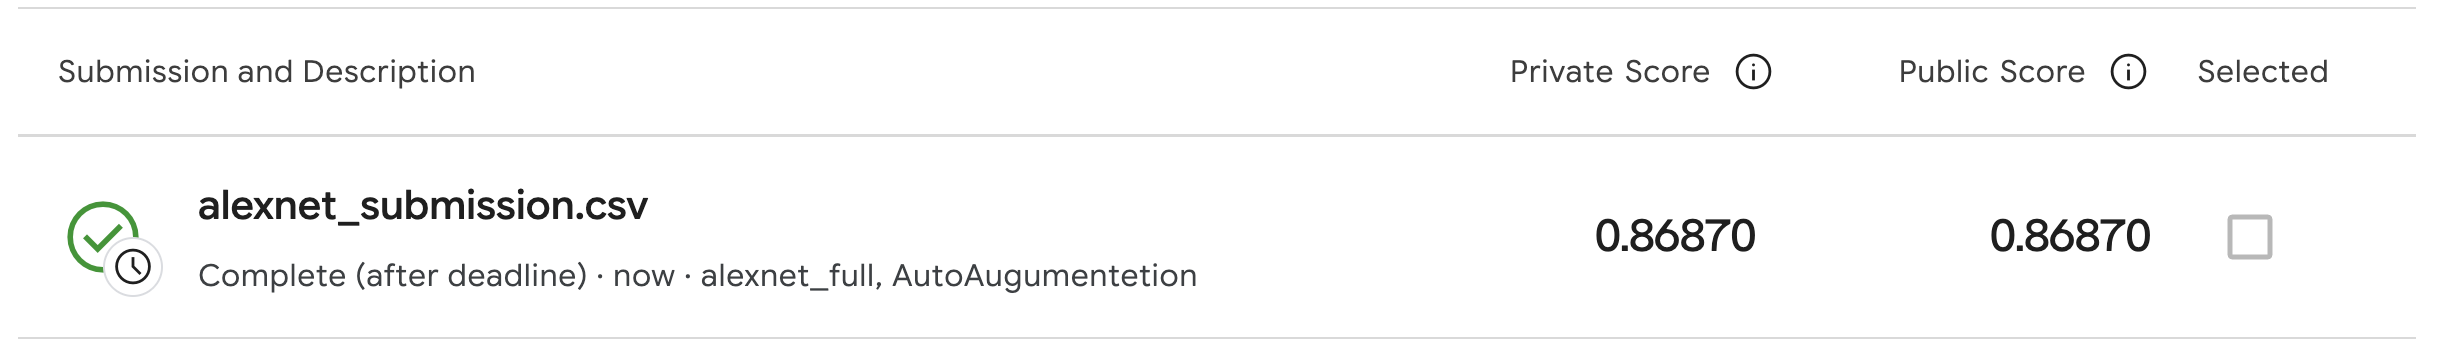
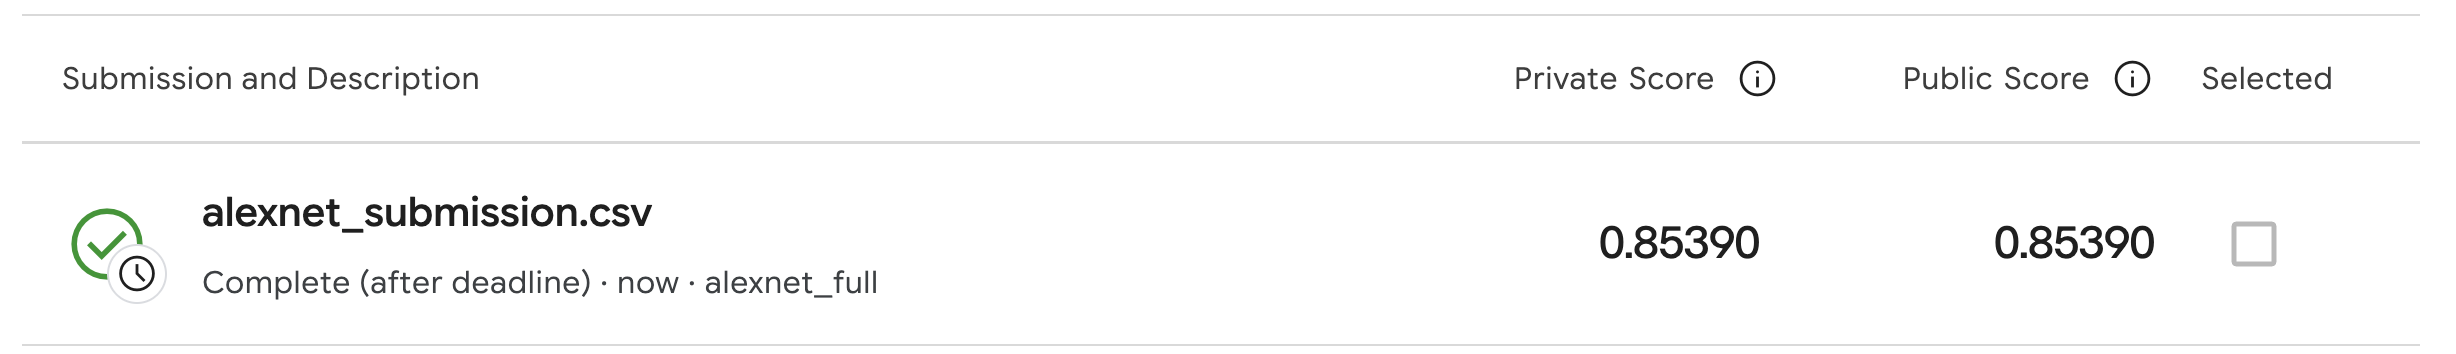

## Итог

AlexNet адаптирована для изображений CIFAR-10 размером 32×32. При обучении используются поканальная стандартизация и готовая стратегия аугментаций `AutoAugmentPolicy.CIFAR10`.

Финальная модель обучалась на всех **50 000 изображениях train в течение 200 эпох**. Для предсказаний использованы веса последней эпохи.

Итоговый файл предсказаний получил **86,87% accuracy на Kaggle**.
